In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
embeddings = np.load("../dataset/embeddings.npy")

print("Embedding shape:", embeddings.shape)
print("Embedding dimension:", embeddings.shape[1])

Embedding shape: (20, 384)
Embedding dimension: 384


In [3]:
similarity_matrix = cosine_similarity(embeddings)

print("Similarity Matrix:")
print(similarity_matrix)

Similarity Matrix:
[[ 9.99999881e-01  5.77876329e-01  5.24880409e-01  5.86006582e-01
   6.26940370e-01  1.84497803e-01  2.32029676e-01  1.28422499e-01
   1.24453008e-01  3.14422220e-01  3.09208006e-01  5.19421339e-01
   3.61916006e-01  4.83203739e-01  4.67387438e-01  3.26469541e-01
   1.13640316e-01  2.70651191e-01  2.00465679e-01  6.07494831e-01]
 [ 5.77876329e-01  9.99999881e-01  4.97379363e-01  5.34893751e-01
   4.91956174e-01  2.11402848e-01  2.60040611e-01  9.37421471e-02
   1.13536991e-01  2.27481812e-01  3.18667561e-01  3.57247889e-01
   4.88324046e-01  5.97358823e-01  3.23641956e-01  2.85261095e-01
   6.99321330e-02  2.49266669e-01  1.77875310e-01  4.87863123e-01]
 [ 5.24880409e-01  4.97379363e-01  1.00000000e+00  3.99299860e-01
   4.54263687e-01  1.64993331e-01  2.06125855e-01  2.59149186e-02
   5.59152216e-02  1.98797792e-01  1.08504303e-01  2.60516077e-01
   2.55133152e-01  4.09894884e-01  2.65184253e-01  6.48710430e-02
   1.23919778e-01  1.22906506e-01  1.54703289e-01  4.40

In [4]:
similarity_matrix = cosine_similarity(embeddings)

In [5]:
sentences = pd.read_csv("../dataset/generated_text.csv")["sentence"]

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=range(1, 21),
    columns=range(1, 21)
)

similarity_df

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
1,1.000000,0.577876,0.524880,0.586007,0.626940,0.184498,0.232030,0.128422,0.124453,0.314422,0.309208,0.519421,0.361916,0.483204,0.467387,0.326470,0.113640,0.270651,0.200466,0.607495
2,0.577876,1.000000,0.497379,0.534894,0.491956,0.211403,0.260041,0.093742,0.113537,0.227482,0.318668,0.357248,0.488324,0.597359,0.323642,0.285261,0.069932,0.249267,0.177875,0.487863
3,0.524880,0.497379,1.000000,0.399300,0.454264,0.164993,0.206126,0.025915,0.055915,0.198798,0.108504,0.260516,0.255133,0.409895,0.265184,0.064871,0.123920,0.122907,0.154703,0.440081
4,0.586007,0.534894,0.399300,1.000000,0.428263,0.203495,0.332193,0.048209,0.132380,0.270528,0.262108,0.406395,0.336721,0.474700,0.214605,0.200612,0.112429,0.347832,0.158865,0.388399
5,0.626940,0.491956,0.454264,0.428263,1.000000,0.433011,0.426210,0.093147,0.064498,0.336234,0.241997,0.369090,0.252226,0.392384,0.323700,0.197888,0.135351,0.214464,0.391712,0.573423
6,0.184498,0.211403,0.164993,0.203495,0.433011,1.000000,0.272892,0.020010,-0.018605,0.161080,0.331940,0.168336,0.174115,0.152759,0.111421,0.180709,0.081343,0.284114,0.261160,0.307517
7,0.232030,0.260041,0.206126,0.332193,0.426210,0.272892,1.000000,0.276621,0.233528,0.227039,0.106835,0.120793,0.190766,0.176276,0.072240,0.066601,0.137665,0.198750,0.350139,0.198217
8,0.128422,0.093742,0.025915,0.048209,0.093147,0.020010,0.276621,1.000000,0.522485,0.248459,0.073221,0.033369,0.094089,0.047601,0.134665,0.043010,0.215653,0.142783,0.243649,0.126313
9,0.124453,0.113537,0.055915,0.132380,0.064498,-0.018605,0.233528,0.522485,1.000000,0.094838,0.088286,0.000112,0.063127,0.095576,0.067532,0.016077,0.251980,0.112965,0.258960,0.053404
10,0.314422,0.227482,0.198798,0.270528,0.336234,0.161080,0.227039,0.248459,0.094838,1.000000,0.248700,0.172009,0.169975,0.270488,0.221990,0.161652,0.126177,0.279215,0.251739,0.490983


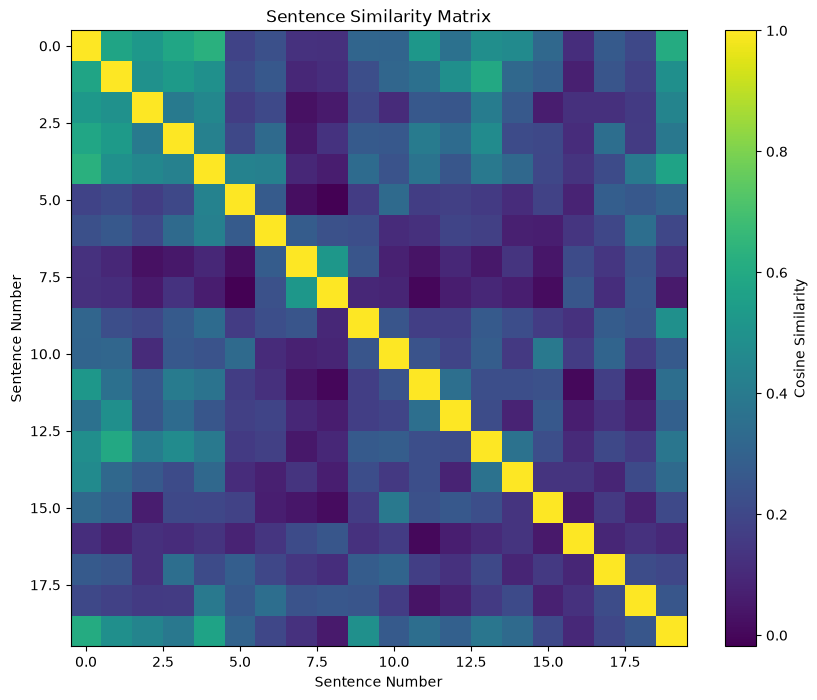

In [6]:
plt.figure(figsize=(10, 8))

plt.imshow(similarity_matrix)

plt.xlabel("Sentence Number")
plt.ylabel("Sentence Number")
plt.title("Sentence Similarity Matrix")

plt.colorbar(label="Cosine Similarity")
plt.show()

In [7]:
pairs_df = pd.read_csv("../dataset/similarity_scores.csv")

top_5 = pairs_df.sort_values(
    by="similarity_score",
    ascending=False
).head(5)

top_5

,sentence_1,sentence_2,similarity_score
0,Artificial intelligence helps computers perfor...,Students can use artificial intelligence to im...,0.626941
1,Artificial intelligence helps computers perfor...,Artificial intelligence can support many appli...,0.607495
4,Natural language processing helps computers un...,Artificial intelligence helps computers perfor...,0.586006
6,Regular exercise helps people maintain a healt...,Eating nutritious food provides energy for dai...,0.522485
2,Machine learning allows computers to learn pat...,Data science combines statistics programming a...,0.488324


In [8]:
for index, row in top_5.iterrows():
    print("Sentence 1:", row["sentence_1"])
    print("Sentence 2:", row["sentence_2"])
    print("Similarity Score:", round(row["similarity_score"], 4))
    print("-" * 80)

Sentence 1: Artificial intelligence helps computers perform tasks that normally require human intelligence.
Sentence 2: Students can use artificial intelligence to improve their learning experience.
Similarity Score: 0.6269
--------------------------------------------------------------------------------
Sentence 1: Artificial intelligence helps computers perform tasks that normally require human intelligence.
Sentence 2: Artificial intelligence can support many applications in education healthcare and business.
Similarity Score: 0.6075
--------------------------------------------------------------------------------
Sentence 1: Natural language processing helps computers understand human language.
Sentence 2: Artificial intelligence helps computers perform tasks that normally require human intelligence.
Similarity Score: 0.586
--------------------------------------------------------------------------------
Sentence 1: Regular exercise helps people maintain a healthy lifestyle.
Sentence 

In [9]:
comparison = pd.read_csv("../dataset/sentence_pairs.csv")

comparison

,sentence_1,sentence_2,similarity_score
0,Artificial intelligence helps computers perfor...,Students can use artificial intelligence to im...,0.626941
1,Artificial intelligence helps computers perfor...,Artificial intelligence can support many appli...,0.607495
2,Machine learning allows computers to learn pat...,Data science combines statistics programming a...,0.488324
3,Deep learning uses neural networks to solve co...,Computer vision enables machines to understand...,0.409895
4,Natural language processing helps computers un...,Artificial intelligence helps computers perfor...,0.586006
5,Online education provides flexible learning op...,Reading books regularly can improve knowledge ...,0.272892
6,Regular exercise helps people maintain a healt...,Eating nutritious food provides energy for dai...,0.522485
7,Cloud computing allows users to access computi...,Python is a popular programming language used ...,0.241783
8,Robots can perform repetitive tasks in factori...,Renewable energy sources can help reduce envir...,0.136279
9,Social media allows people to communicate and ...,Good time management helps students complete t...,0.219932


## Similar vs Unrelated Sentence Pairs

Sentence pairs with similar meanings generally have 
higher cosine similarity
scores because their embeddings are closer in the vector space.

Unrelated sentence pairs generally have lower cosine similarity scores because
their meanings and semantic contexts are different.

For example, sentences related to Artificial Intelligence and Machine Learning
are expected to have higher similarity, while sentences about unrelated topics
such as social media and time management may have lower similarity.